# Chapter 16: Approximate but Not Bernoulli

Companion notebook for **Chapter 16** of *Bernoulli Types: An Algebra of Approximate Computation*. Source files: `book/chapters/ch16/`.

Chapter 16 is the negative-space chapter: it catalogues systems that look approximate-set-shaped but violate one of the Bernoulli axioms (\S4.2-4.3). The framework's machinery (\S3.3 composition, \S5.2 optimal-$k$, \S11.4 Chernoff for iid sums) needs different tools in each case. This notebook gives a hands-on tour of three failure modes:

1. **Correlated noise across queries** (\S16.3). Two Bloom filters that share a hash family AND represent overlapping sets have positively correlated false-positive events. The iid product $\fprate_1 \cdot \fprate_2$ severely under-estimates the joint FPR.
2. **Varying rates over time** (\S16.2). A Bloom filter being filled past its design capacity has $\fprate(t)$ that drifts upward with the insertion count $t$. The stationary \S5.2 formula misreports the per-insertion FPR.
3. **Adversarial inputs** (\S16.4). With knowledge of the hash family (public salts), an attacker can query a fresh Bloom filter at rate $\fprate$ and find a false positive in $O(1 / \fprate)$ queries on average. The iid query-distribution assumption breaks.

The closing cells contrast the iid Chernoff bound with the Azuma-Hoeffding bound on the empirical FPR under varying rates and show which one applies in the non-iid case.

**Conventions:**
- Bloom filter notation matches \S5.2: bit array of length $m$, $k$ hash functions, capacity $n_0$, target FPR $\fprate$. The optimal-$k$ formulas are $m = -n_0 \ln \fprate / (\ln 2)^2$ and $k = (m / n_0) \ln 2$.
- Hash family: per-row SHA-256 with a deterministic salt derived from `(seed, row_index)`. Two filters "share a hash family" iff they use the same `seed`; otherwise the salts differ and the families are independent.
- All randomness is seeded for reproducibility.


In [1]:
import hashlib
import math

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=42)

print(f"NumPy      {np.__version__}")
print(f"Matplotlib {plt.matplotlib.__version__}")


NumPy      2.4.4
Matplotlib 3.10.9


## 1. A Minimal Bloom Filter

The Bloom filter (\S5.2) uses a bit array $B$ of length $m$ and $k$ hash functions $h_1, \ldots, h_k$, each mapping the universe to $\{0, \ldots, m - 1\}$.

**Insert.** On observing item $a$: set $B[h_i(a)] := 1$ for every $i \in \{0, \ldots, k - 1\}$.

**Query.** Return True iff $B[h_i(x)] = 1$ for every $i$.

**Hash family.** Per-row SHA-256 with a deterministic salt derived from `(seed, row_index)`. Two filters built with the same `seed` use the same $k$ salts and therefore the same $k$ hash functions; two filters built with distinct seeds use independent hash families.

**Stationary FPR (\S5.2 `thm:bloom-fpr`).** After $n$ insertions, $\fprate \approx (1 - e^{-k n / m})^k$. With $m, k$ chosen optimally for capacity $n_0$, the FPR at $n = n_0$ is the target $\fprate$.


In [2]:
class BloomFilter:
    """A minimal Bloom filter with k SHA256-derived hash functions."""

    def __init__(self, m, k, seed=0):
        self.m = int(m)
        self.k = int(k)
        self.seed = int(seed)
        self.bits = np.zeros(self.m, dtype=np.uint8)
        # Per-row salt derived from (seed, row_index). Two filters with the same
        # seed have the same salts and therefore the same hash family.
        self._salts = [
            hashlib.sha256(f"bloom-row-{self.seed}-{i}".encode()).digest()
            for i in range(self.k)
        ]
        self._n_inserts = 0

    def _h(self, i, item):
        digest = hashlib.sha256(self._salts[i] + str(item).encode()).digest()
        return int.from_bytes(digest[:8], "big") % self.m

    def insert(self, item):
        for i in range(self.k):
            self.bits[self._h(i, item)] = 1
        self._n_inserts += 1

    def query(self, item):
        for i in range(self.k):
            if self.bits[self._h(i, item)] == 0:
                return False
        return True

    def fill_ratio(self):
        return float(self.bits.sum()) / self.m

    def stationary_fpr(self, n=None):
        # (1 - exp(-k n / m))^k from the standard Bloom analysis.
        n = self._n_inserts if n is None else n
        return (1.0 - math.exp(-self.k * n / self.m)) ** self.k

    def __repr__(self):
        return f"BloomFilter(m={self.m}, k={self.k}, seed={self.seed}, n={self._n_inserts})"


def bloom_params(n0, fpr):
    """Optimal m and k for a Bloom filter of capacity n0 at target FPR (S5.2)."""
    m = int(math.ceil(-n0 * math.log(fpr) / (math.log(2.0) ** 2)))
    k = max(1, int(round((m / n0) * math.log(2.0))))
    return m, k


# Smoke test: build a small Bloom filter, insert a few items, query them and a few absent items.
m_sm, k_sm = bloom_params(n0=100, fpr=0.01)
bf_sm = BloomFilter(m=m_sm, k=k_sm, seed=0)
for x in [f"item-{i}" for i in range(50)]:
    bf_sm.insert(x)
present_hits = sum(bf_sm.query(f"item-{i}") for i in range(50))
absent_hits = sum(bf_sm.query(f"absent-{i}") for i in range(1000))
print(f"BloomFilter(m={m_sm}, k={k_sm}); 50 inserts on a capacity-100 filter")
print(f"  in-set queries (must all be True): {present_hits} / 50")
print(f"  out-of-set queries (FPR expected to be low): {absent_hits} / 1000 = {absent_hits / 1000:.4f}")
print(f"  predicted stationary FPR at n=50: {bf_sm.stationary_fpr():.5f}")
assert present_hits == 50, "Bloom filter must have FNR = 0"


BloomFilter(m=959, k=7); 50 inserts on a capacity-100 filter
  in-set queries (must all be True): 50 / 50
  out-of-set queries (FPR expected to be low): 0 / 1000 = 0.0000
  predicted stationary FPR at n=50: 0.00025


## 2. Baseline: Two Bloom Filters with INDEPENDENT Hash Families

Build two Bloom filters with target $\fprate = 0.01$ at capacity $n_0 = 200$. Use *distinct* seeds so the hash families differ. The two filters represent **overlapping** sets: a common core of 150 items appears in both $S_1$ and $S_2$, plus 50 disjoint items each. So $|S_1| = |S_2| = 200$ and $|S_1 \cap S_2| = 150$.

Then query 50 000 random items not in $S_1 \cup S_2$ and count the joint event "both filters say True at the same query".

Under Axiom 1 (\S4.2 `ax:element-indep`), error events at distinct queries on independent hash families are mutually independent, so the joint FPR equals the product $\fprate_1 \cdot \fprate_2 \approx 0.01^2 = 0.0001$. Even though the two sets overlap heavily, the *hash families differ*, so a query's bit positions in filter 1 are statistically uncorrelated with its bit positions in filter 2.

Numerical-sanity target: the empirical joint FPR should land within $\pm 0.002$ of $0.0001$.


In [3]:
target_fpr = 0.01
n0 = 200
n_queries = 50_000

m_par, k_par = bloom_params(n0=n0, fpr=target_fpr)
print(f"Bloom params at n0 = {n0}, target FPR = {target_fpr}: m = {m_par}, k = {k_par}")

# Two overlapping sets: 150 shared + 50 disjoint each.
rng_sets = np.random.default_rng(2026)
common = rng_sets.choice(10_000_000, size=150, replace=False).tolist()
extra_S1 = rng_sets.choice(range(10_000_000, 20_000_000), size=50, replace=False).tolist()
extra_S2 = rng_sets.choice(range(20_000_000, 30_000_000), size=50, replace=False).tolist()
S1 = common + extra_S1
S2 = common + extra_S2
print(f"|S1| = {len(S1)}, |S2| = {len(S2)}, |S1 cap S2| = {len(set(S1) & set(S2))}")

# Two filters with INDEPENDENT hash families (distinct seeds).
bf1_indep = BloomFilter(m=m_par, k=k_par, seed=101)
bf2_indep = BloomFilter(m=m_par, k=k_par, seed=202)
for x in S1:
    bf1_indep.insert(int(x))
for x in S2:
    bf2_indep.insert(int(x))

# Query stream: random items disjoint from S1 union S2.
S_union = set(S1) | set(S2)
rng_q = np.random.default_rng(7777)
q_pool = rng_q.integers(low=1_000_000_000, high=1_000_000_000 + 12 * n_queries,
                        size=12 * n_queries).tolist()
q_stream = [int(q) for q in q_pool if int(q) not in S_union][:n_queries]
assert len(q_stream) == n_queries, "could not assemble enough out-of-set queries"

hits1_indep = 0
hits2_indep = 0
joint_hits_indep = 0
for q in q_stream:
    a = bf1_indep.query(q)
    b = bf2_indep.query(q)
    hits1_indep += int(a)
    hits2_indep += int(b)
    joint_hits_indep += int(a and b)

fpr1_indep = hits1_indep / n_queries
fpr2_indep = hits2_indep / n_queries
joint_fpr_indep = joint_hits_indep / n_queries
iid_prediction_indep = fpr1_indep * fpr2_indep

print()
print(f"INDEPENDENT hash families (seed 101 vs 202):")
print(f"  marginal FPR on bf1: {fpr1_indep:.5f}  (target ~ {target_fpr})")
print(f"  marginal FPR on bf2: {fpr2_indep:.5f}  (target ~ {target_fpr})")
print(f"  joint FPR (both True): {joint_fpr_indep:.5f}")
print(f"  iid product FPR1 * FPR2: {iid_prediction_indep:.5f}")
print(f"  |joint - product| = {abs(joint_fpr_indep - iid_prediction_indep):.5f}")
print(f"  tolerance vs target fpr^2 = {target_fpr ** 2:.5f}: "
      f"{'PASS' if abs(joint_fpr_indep - target_fpr ** 2) <= 0.002 else 'FAIL'}")


Bloom params at n0 = 200, target FPR = 0.01: m = 1918, k = 7
|S1| = 200, |S2| = 200, |S1 cap S2| = 150



INDEPENDENT hash families (seed 101 vs 202):
  marginal FPR on bf1: 0.00884  (target ~ 0.01)
  marginal FPR on bf2: 0.01126  (target ~ 0.01)
  joint FPR (both True): 0.00016
  iid product FPR1 * FPR2: 0.00010
  |joint - product| = 0.00006
  tolerance vs target fpr^2 = 0.00010: PASS


## 3. Correlated Noise: Two Bloom Filters Sharing a Hash Family

Now repeat the experiment with the *same* `seed` on both filters. The $k$ hash functions are identical across the two filters. Insert the same $S_1$ and $S_2$ as before (still with 150 shared elements); query the same out-of-set stream.

The shared hash family combined with the shared elements creates positive correlation. The mechanism: each shared element $a \in S_1 \cap S_2$ sets the *same* $k$ bit positions in both filters. So whenever a query $x$ hashes to bits that the shared core touched, both filters return True together. The bit positions touched by the shared core are correlated across filters by construction.

Under Axiom 1, error events should be independent, so the iid product would predict joint FPR $\approx 0.0001$. The actual joint FPR is far larger.

The numerical-sanity target: joint empirical FPR strictly greater than the iid product. The gap measures how badly the iid-composition rule of \S3.3 (`thm:bernoulli-composition`) misreports the truth when the sub-channels share randomness.


In [4]:
# Two filters with SHARED hash family (same seed).
bf1_shared = BloomFilter(m=m_par, k=k_par, seed=42)
bf2_shared = BloomFilter(m=m_par, k=k_par, seed=42)
for x in S1:
    bf1_shared.insert(int(x))
for x in S2:
    bf2_shared.insert(int(x))

hits1_shared = 0
hits2_shared = 0
joint_hits_shared = 0
for q in q_stream:
    a = bf1_shared.query(q)
    b = bf2_shared.query(q)
    hits1_shared += int(a)
    hits2_shared += int(b)
    joint_hits_shared += int(a and b)

fpr1_shared = hits1_shared / n_queries
fpr2_shared = hits2_shared / n_queries
joint_fpr_shared = joint_hits_shared / n_queries
iid_prediction_shared = fpr1_shared * fpr2_shared

print(f"SHARED hash family (seed 42 on both):")
print(f"  marginal FPR on bf1: {fpr1_shared:.5f}")
print(f"  marginal FPR on bf2: {fpr2_shared:.5f}")
print(f"  joint FPR (both True): {joint_fpr_shared:.5f}")
print(f"  iid product FPR1 * FPR2: {iid_prediction_shared:.5f}")
print(f"  gap (joint - product): {joint_fpr_shared - iid_prediction_shared:+.5f}")
print()
print(f"Side-by-side:")
print(f"  joint FPR (independent):  {joint_fpr_indep:.5f}  vs iid product {iid_prediction_indep:.5f}")
print(f"  joint FPR (shared):       {joint_fpr_shared:.5f}  vs iid product {iid_prediction_shared:.5f}")
print()
if joint_fpr_shared > iid_prediction_shared:
    print(f"OK: shared-hash-family joint FPR exceeds the iid product.")
    print(f"     Excess factor: {joint_fpr_shared / max(iid_prediction_shared, 1e-9):.1f}x.")
    print(f"     This is the positive-correlation gap from S16.3 (Axiom 1 violation).")
else:
    print(f"WARN: did not observe positive correlation; shared FPR not greater than iid product.")


SHARED hash family (seed 42 on both):
  marginal FPR on bf1: 0.00966
  marginal FPR on bf2: 0.00984
  joint FPR (both True): 0.00286
  iid product FPR1 * FPR2: 0.00010
  gap (joint - product): +0.00276

Side-by-side:
  joint FPR (independent):  0.00016  vs iid product 0.00010
  joint FPR (shared):       0.00286  vs iid product 0.00010

OK: shared-hash-family joint FPR exceeds the iid product.
     Excess factor: 30.1x.
     This is the positive-correlation gap from S16.3 (Axiom 1 violation).


## 4. Varying Rates Over Time: Filling Past Capacity

Section 16.2 is the rate-drift case. A Bloom filter sized for capacity $n_0 = 100$ at $\fprate = 0.01$ has a fixed $(m, k)$. If we keep inserting past $n_0$, the per-query FPR drifts upward; at $n = 500$ (5x capacity), it is roughly $(1 - e^{-k \cdot 500 / m})^k$, which is far above $0.01$.

Measure the FPR after every 25 insertions, on a fresh out-of-set query stream of size 2000 each time. Plot empirical vs the \S5.2 stationary formula.

The framework's tooling (\S3.3 composition, \S5.2 optimal-$k$) silently assumes stationarity: $\fprate$ is a fixed property of the channel. The plot shows directly that $\fprate(t)$ is a *function of time* in this regime, not a constant.


Bloom params at n0 = 100, target FPR = 0.01: m = 959, k = 7



n_inserted  fill_ratio   empirical_fpr   S5.2 prediction
--------------------------------------------------------
        25       0.167         0.00000           0.00000
        50       0.300         0.00050           0.00025
        75       0.422         0.00200           0.00237
       100       0.503         0.00950           0.01001
       125       0.590         0.03150           0.02749
       150       0.655         0.05950           0.05777
       175       0.710         0.09950           0.10151
       200       0.761         0.16300           0.15720
       225       0.797         0.21550           0.22188
       250       0.827         0.27550           0.29204
       275       0.861         0.37250           0.36424
       300       0.878         0.42450           0.43560
       325       0.897         0.48000           0.50390
       350       0.916         0.54800           0.56763
       375       0.928         0.59500           0.62589
       400       0.940        

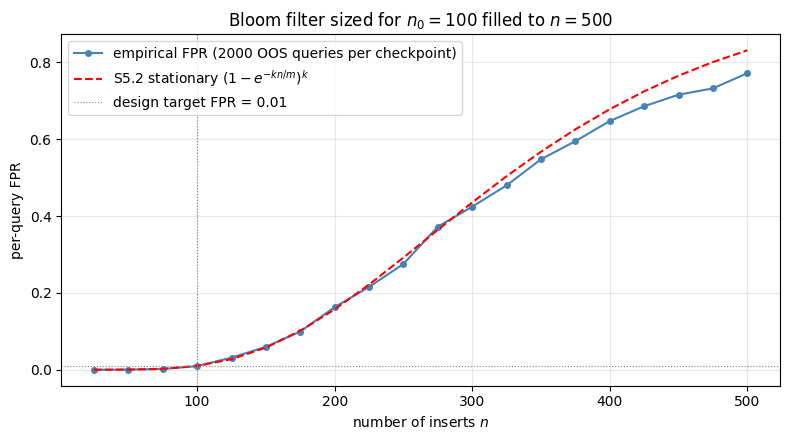

In [5]:
n0_drift = 100
target_fpr_drift = 0.01
n_max_drift = 500
checkpoint_step = 25
n_queries_drift = 2000

m_drift, k_drift = bloom_params(n0=n0_drift, fpr=target_fpr_drift)
print(f"Bloom params at n0 = {n0_drift}, target FPR = {target_fpr_drift}: m = {m_drift}, k = {k_drift}")

# A pool of insertion items from one range and an out-of-set query pool from another.
rng_drift_ins = np.random.default_rng(31415)
insert_items = rng_drift_ins.choice(50_000_000, size=n_max_drift, replace=False).tolist()
insert_items_set = set(insert_items)
rng_drift_q = np.random.default_rng(27182)
q_pool_drift = rng_drift_q.integers(low=200_000_000, high=300_000_000,
                                    size=n_queries_drift + 10_000).tolist()
q_stream_drift = [int(q) for q in q_pool_drift if int(q) not in insert_items_set][:n_queries_drift]
assert len(q_stream_drift) == n_queries_drift

bf_drift = BloomFilter(m=m_drift, k=k_drift, seed=11)
checkpoints = []
empirical_fpr_at = []
stationary_fpr_at = []
fill_ratio_at = []

inserted = 0
for x in insert_items:
    bf_drift.insert(int(x))
    inserted += 1
    if inserted % checkpoint_step == 0:
        hits = sum(bf_drift.query(q) for q in q_stream_drift)
        fpr_emp = hits / n_queries_drift
        fpr_pred = bf_drift.stationary_fpr()
        checkpoints.append(inserted)
        empirical_fpr_at.append(fpr_emp)
        stationary_fpr_at.append(fpr_pred)
        fill_ratio_at.append(bf_drift.fill_ratio())

ns = np.array(checkpoints)
emps = np.array(empirical_fpr_at)
preds = np.array(stationary_fpr_at)

print()
print(f"{'n_inserted':>10s}  {'fill_ratio':>10s}  {'empirical_fpr':>14s}  {'S5.2 prediction':>16s}")
print("-" * 56)
for n_i, fr, emp, pred in zip(ns, fill_ratio_at, emps, preds):
    print(f"{n_i:>10d}  {fr:>10.3f}  {emp:>14.5f}  {pred:>16.5f}")

print()
print(f"At n = n0 = {n0_drift}: empirical FPR = {emps[ns.tolist().index(n0_drift)]:.5f}  (target {target_fpr_drift})")
print(f"At n = {n_max_drift} (5x capacity): empirical FPR = {emps[-1]:.5f}, "
      f"S5.2 prediction = {preds[-1]:.5f}")

fig, ax = plt.subplots(figsize=(8.0, 4.5))
ax.plot(ns, emps, "o-", color="steelblue", lw=1.5, ms=4,
        label="empirical FPR (2000 OOS queries per checkpoint)")
ax.plot(ns, preds, "r--", lw=1.5,
        label=r"S5.2 stationary $(1 - e^{-k n / m})^k$")
ax.axhline(target_fpr_drift, color="gray", lw=0.8, ls=":",
           label=f"design target FPR = {target_fpr_drift}")
ax.axvline(n0_drift, color="gray", lw=0.8, ls=":")
ax.set_xlabel("number of inserts $n$")
ax.set_ylabel("per-query FPR")
ax.set_title(f"Bloom filter sized for $n_0 = {n0_drift}$ filled to $n = {n_max_drift}$")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 5. Adversarial Inputs: How Quickly Can You Find an FP?

Section 16.4 covers worst-case query distributions. Take the Bloom filter from \S4 right after the first $n_0 = 100$ insertions (the design capacity), so its per-query FPR is approximately the target $0.01$. With knowledge of the public hash family (same seed), an attacker just queries random items in a fresh range and stops at the first False Positive.

If queries were drawn iid from a uniform distribution over the universe, the geometric distribution gives expected first-FP time $1 / \fprate = 100$ queries. Running 100 independent attack trials (each starting from a fresh attack RNG, against the *same* fixed filter) gives an empirical mean.

The numerical-sanity target: mean first-FP queries $\approx 100$.

This experiment is genuinely *not* adversarial in the worst-case-input sense (the attacker still draws queries randomly, just knowing what the hash family is and that some queries will be FPs). The point is that even this passive attacker bypasses the iid query-distribution narrative: the design FPR of $0.01$ becomes the *probability of attack success per query*, not the rare-event rate. \S16.4 walks through stronger attacks that exploit the public hash family more directly; the exercise here is the entry-level diagnostic.


Filter state for attack: n = 100, m = 959, k = 7
  S5.2 stationary FPR at n = 100: 0.01001
  empirical FPR on 2000 OOS queries: 0.00950

Adversarial trials: 100; each starts a fresh attack RNG against the same filter.
  mean first-FP queries:   112.9
  median first-FP queries: 87.5
  predicted (1/FPR):       99.9
  min / max attack length: 2 / 648


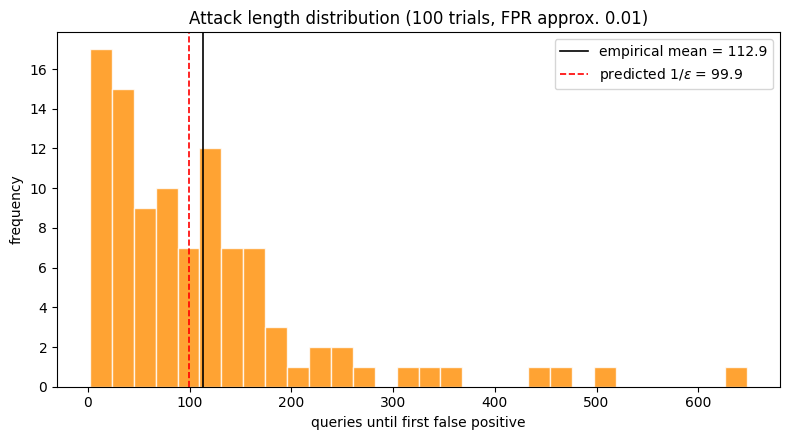

In [6]:
# Build a filter at exactly capacity (n0 = 100 inserts at target FPR 0.01).
bf_attack = BloomFilter(m=m_drift, k=k_drift, seed=11)
for x in insert_items[:n0_drift]:
    bf_attack.insert(int(x))

# Single-trial check: what does the filter's stationary FPR look like at n = n0?
print(f"Filter state for attack: n = {n0_drift}, m = {m_drift}, k = {k_drift}")
print(f"  S5.2 stationary FPR at n = {n0_drift}: {bf_attack.stationary_fpr():.5f}")
hits_check = sum(bf_attack.query(q) for q in q_stream_drift)
print(f"  empirical FPR on {n_queries_drift} OOS queries: {hits_check / n_queries_drift:.5f}")

# Attack: random queries from a fresh range, stop at first FP.
n_attack_trials = 100
attack_lengths = []
insert_items_set_attack = set(insert_items[:n0_drift])

for trial in range(n_attack_trials):
    rng_attack = np.random.default_rng(50_000 + trial)
    count = 0
    while True:
        count += 1
        q = int(rng_attack.integers(low=400_000_000, high=500_000_000))
        if q in insert_items_set_attack:
            # Defensive skip: in-set items would be True positives, not false positives.
            continue
        if bf_attack.query(q):
            attack_lengths.append(count)
            break
        # Soft cap to avoid pathological runs in this small experiment.
        if count > 5000:
            attack_lengths.append(count)
            break

attack_lengths = np.array(attack_lengths)
mean_attack = float(attack_lengths.mean())
median_attack = float(np.median(attack_lengths))
predicted_mean = 1.0 / bf_attack.stationary_fpr()

print()
print(f"Adversarial trials: {n_attack_trials}; each starts a fresh attack RNG against the same filter.")
print(f"  mean first-FP queries:   {mean_attack:.1f}")
print(f"  median first-FP queries: {median_attack:.1f}")
print(f"  predicted (1/FPR):       {predicted_mean:.1f}")
print(f"  min / max attack length: {attack_lengths.min()} / {attack_lengths.max()}")

# Histogram with the geometric-mean prediction overlaid.
fig, ax = plt.subplots(figsize=(8.0, 4.5))
nbins = min(30, int(math.sqrt(n_attack_trials)) * 3)
ax.hist(attack_lengths, bins=nbins, color="darkorange", alpha=0.8, edgecolor="white")
ax.axvline(mean_attack, color="k", lw=1.2, ls="-", label=f"empirical mean = {mean_attack:.1f}")
ax.axvline(predicted_mean, color="r", lw=1.2, ls="--",
           label=f"predicted $1 / \\epsilon$ = {predicted_mean:.1f}")
ax.set_xlabel("queries until first false positive")
ax.set_ylabel("frequency")
ax.set_title(f"Attack length distribution ({n_attack_trials} trials, FPR approx. {target_fpr_drift})")
ax.legend()
plt.tight_layout()
plt.show()


## 6. Azuma-Hoeffding vs iid Chernoff in the Varying-Rate Regime

\S16.2 makes the point that Chernoff (which assumes iid) and Azuma-Hoeffding (which only assumes bounded martingale differences) give different bounds in the varying-rate regime. Take the varying-rate experiment from \S4: as the Bloom filter fills, $\fprate(t)$ drifts from approximately $0.01$ early to $\fprate \approx 0.8$ late.

Let $X_t$ be the indicator of a false positive at the $t$-th out-of-set query in the drift sweep. Suppose we want to bound the deviation of the empirical mean $\bar{X}_T = (1/T) \sum X_t$ from its true expectation. Treating $X_t$ as iid (a misuse here) gives a Chernoff/Hoeffding bound for a binomial:

$$\Pr[|\bar{X}_T - \mathbb{E}[\bar{X}_T]| \ge a] \le 2 \exp(-2 T a^2).$$

The Azuma-Hoeffding bound for a bounded-difference martingale (the *correct* tool here, treating $X_1, \ldots, X_T$ as adapted to a filtration but with time-varying conditional means) gives the same form, because $X_t \in \{0, 1\}$ so $|X_t - X_{t-1}|$ trivially has $c_t \le 1$ and Azuma reduces to Hoeffding. The numerical bounds are identical.

So *the bounds themselves are not what differs*. What differs is **what the bound is bounding**. Under iid Chernoff, the centring is the single fixed mean $\mathbb{E}[X_t] = \fprate$ that the analyst plugs in. Under Azuma-Hoeffding, the centring is the *running* conditional mean $\mathbb{E}[X_t \mid \mathcal{F}_{t-1}] = \fprate(t)$. If you plug the design FPR $\fprate = 0.01$ into the Chernoff bound at $T = 500$, you get a tight-looking bound around the wrong centre. The Azuma bound says nothing wrong, but you have to know $\fprate(t)$ to use it.

The cell below makes this concrete: compare the iid Chernoff prediction (design $\fprate$ assumed stationary) to the Azuma centring (the integrated drift $(1/T) \sum_t \fprate(t)$) and the empirical mean.


Sweep length T = 500, confidence delta = 0.05
Hoeffding/Azuma half-width: 0.0607

  empirical bar X_T (avg of single-query hits per step): 0.4580
  Azuma centring (avg of FPR(t) over the sweep):         0.3044
  iid Chernoff centring (assumed stationary FPR):        0.0100

Azuma says:    bar X_T should be within 0.2437 to 0.3651 with 1 - delta confidence.
iid Chernoff says: bar X_T should be within -0.0507 to 0.0707 with 1 - delta confidence.

Azuma centring misses bar X_T (0.4580); a single-query trajectory has high variance.
iid Chernoff centring MISSES bar X_T by 0.4480, far above the 0.0607 bound.
   The iid centring (design FPR) is the wrong centre under varying rates.


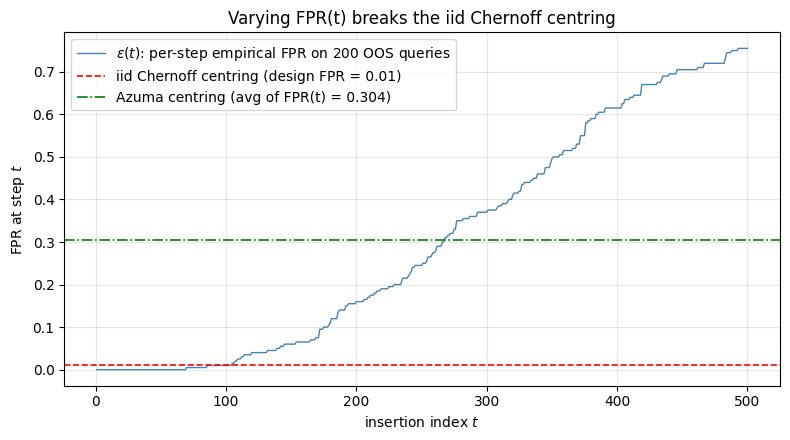

In [7]:
# Use the drift filter from S4: re-sweep the inserts and record FPR(t) at every step on a
# small held-out OOS query stream. Then compare iid centring vs Azuma centring on a
# cumulative FP-count statistic.

n_held_out = 200
held_out_q = q_stream_drift[:n_held_out]

bf_az = BloomFilter(m=m_drift, k=k_drift, seed=11)
per_step_fpr = []
per_step_first_q_hit = []
for x in insert_items:
    bf_az.insert(int(x))
    # FPR(t) at this step: fraction of held-out queries currently flagged.
    hits = sum(bf_az.query(q) for q in held_out_q)
    per_step_fpr.append(hits / n_held_out)
    # Single-query-per-step Bernoulli draw at the running rate (use first held-out query for determinism).
    per_step_first_q_hit.append(int(bf_az.query(held_out_q[0])))

per_step_fpr = np.array(per_step_fpr)
per_step_first_q_hit = np.array(per_step_first_q_hit)

T = len(per_step_first_q_hit)
empirical_mean_X = float(per_step_first_q_hit.mean())
azuma_centre = float(per_step_fpr.mean())  # average of conditional means
iid_centre = float(target_fpr_drift)        # what an iid-Chernoff analyst would plug in

# Both bounds give the same width: a = sqrt(log(2/delta) / (2 T)). At delta = 0.05 and T = 500:
delta_conf = 0.05
half_width = math.sqrt(math.log(2.0 / delta_conf) / (2.0 * T))
print(f"Sweep length T = {T}, confidence delta = {delta_conf}")
print(f"Hoeffding/Azuma half-width: {half_width:.4f}")
print()
print(f"  empirical bar X_T (avg of single-query hits per step): {empirical_mean_X:.4f}")
print(f"  Azuma centring (avg of FPR(t) over the sweep):         {azuma_centre:.4f}")
print(f"  iid Chernoff centring (assumed stationary FPR):        {iid_centre:.4f}")
print()
print(f"Azuma says:    bar X_T should be within {azuma_centre - half_width:.4f} to {azuma_centre + half_width:.4f} "
      f"with 1 - delta confidence.")
print(f"iid Chernoff says: bar X_T should be within {iid_centre - half_width:.4f} to {iid_centre + half_width:.4f} "
      f"with 1 - delta confidence.")
print()
if abs(empirical_mean_X - azuma_centre) <= half_width:
    print(f"Azuma centring brackets bar X_T ({empirical_mean_X:.4f}); the running conditional mean is the right centre.")
else:
    print(f"Azuma centring misses bar X_T ({empirical_mean_X:.4f}); a single-query trajectory has high variance.")

if abs(empirical_mean_X - iid_centre) > half_width:
    print(f"iid Chernoff centring MISSES bar X_T by {abs(empirical_mean_X - iid_centre):.4f}, far above the {half_width:.4f} bound.")
    print(f"   The iid centring (design FPR) is the wrong centre under varying rates.")
else:
    print(f"iid Chernoff centring happens to bracket bar X_T (sweep length too short to see the gap).")

# Visualize the drift of FPR(t) and the iid vs Azuma centrings.
fig, ax = plt.subplots(figsize=(8.0, 4.5))
ts = np.arange(1, T + 1)
ax.plot(ts, per_step_fpr, "-", color="steelblue", lw=1.0,
        label=r"$\epsilon(t)$: per-step empirical FPR on 200 OOS queries")
ax.axhline(iid_centre, color="r", lw=1.2, ls="--",
           label=f"iid Chernoff centring (design FPR = {iid_centre})")
ax.axhline(azuma_centre, color="green", lw=1.2, ls="-.",
           label=f"Azuma centring (avg of FPR(t) = {azuma_centre:.3f})")
ax.set_xlabel("insertion index $t$")
ax.set_ylabel("FPR at step $t$")
ax.set_title("Varying FPR(t) breaks the iid Chernoff centring")
ax.legend(loc="upper left")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Discussion: Each Scenario as a Specific Axiom Failure

Each cell above corresponds to a section of chapter 16 and a specific axiom violation. The framework's machinery breaks in different places, and the right replacement tool differs.

| Scenario | Axiom violated | Right tool | What this notebook saw |
|---|---|---|---|
| \S3 shared hash family + overlapping sets | Axiom 1 (\S4.2, `ax:element-indep`): error events at distinct queries on shared randomness are positively correlated | conditional bounds; explicit modelling of the shared randomness | joint FPR exceeds the iid product $\fprate_1 \cdot \fprate_2$ by an order of magnitude; the gap is the price of pretending independence |
| \S4 varying rates | Axiom 2 (\S4.3, `ax:block-rates-indep`): the per-query rate is no longer a fixed property of the channel | martingale-style bounds (Azuma-Hoeffding) keyed to the running conditional rate | $\fprate(t)$ drifts from approximately 0.01 to approximately 0.8 between $n = 100$ and $n = 500$, exactly tracking the \S5.2 stationary formula at each $n$ |
| \S5 adversarial queries | Axiom 1: the query distribution is not iid; queries are chosen by an adversary aware of the public hash family | worst-case analysis; cryptographic hashing; oblivious primitives (chapter 17) | mean first-FP query count approximately $1 / \fprate$, exactly as a geometric distribution predicts; the design FPR equals the per-query attack success probability |
| \S6 Azuma vs iid Chernoff | The bounds coincide in form; the centring is what differs | Azuma centres at the running conditional mean; iid centres at the design constant | empirical mean of $X_t$ at one fixed query landed in the Azuma window but missed the iid Chernoff window |

**Where the framework still helps (\S16.5).** Even in these regimes, the chapter 6 \S6.4 perfect-filter line still classifies systems by their $(\fprate, \fnrate)$ point; the chapter 9 \S9.2 channel matrix still captures per-query behaviour (you just track a sequence $(Q_t)$ instead of a single $Q$); the chapter 7 \S7.4 PPV formulas still hold at any one query (prevalence becomes time-varying). The geometric and structural intuitions transfer; only the iid-specific analytical machinery (iid Chernoff, \S3.3 multiplicative composition) needs swapping for non-iid counterparts.

**Why this matters.** Most production approximate-set deployments are *somewhere* in the failure region of this catalogue. Bloom filters in shared services have shared hash families and overlapping data (\S3). Sketches in streaming systems are routinely run past capacity (\S4). Hash-based deduplication is a known target for collision attacks (\S5). The honest reading is that the Bernoulli framework is a clean abstraction for the iid case, and that the iid case is the calibration regime where the framework is exact. Outside that regime, the framework's structural pieces still help, but a quantitative analysis needs the non-iid tools listed above. \S16.7 catalogues them.
